
=== Modelo com características: IQ bruto ===
SNR =  -4 dB  ->  acurácia =  25.3%
SNR =  -2 dB  ->  acurácia =  29.0%
SNR =   0 dB  ->  acurácia =  27.1%
SNR =   2 dB  ->  acurácia =  28.2%
SNR =   4 dB  ->  acurácia =  29.8%
SNR =   6 dB  ->  acurácia =  30.9%
SNR =   8 dB  ->  acurácia =  33.8%
SNR =  10 dB  ->  acurácia =  32.6%
SNR =  12 dB  ->  acurácia =  34.3%
SNR =  14 dB  ->  acurácia =  33.4%
SNR =  16 dB  ->  acurácia =  33.6%
SNR =  18 dB  ->  acurácia =  35.2%
SNR =  20 dB  ->  acurácia =  34.2%

=== Modelo com características: Cumulantes ===
SNR =  -4 dB  ->  acurácia =  51.4%
SNR =  -2 dB  ->  acurácia =  52.6%
SNR =   0 dB  ->  acurácia =  58.0%
SNR =   2 dB  ->  acurácia =  68.9%
SNR =   4 dB  ->  acurácia =  73.8%
SNR =   6 dB  ->  acurácia =  74.9%
SNR =   8 dB  ->  acurácia =  99.8%
SNR =  10 dB  ->  acurácia = 100.0%
SNR =  12 dB  ->  acurácia = 100.0%
SNR =  14 dB  ->  acurácia = 100.0%
SNR =  16 dB  ->  acurácia = 100.0%
SNR =  18 dB  ->  acurácia =  99.6%
SNR = 

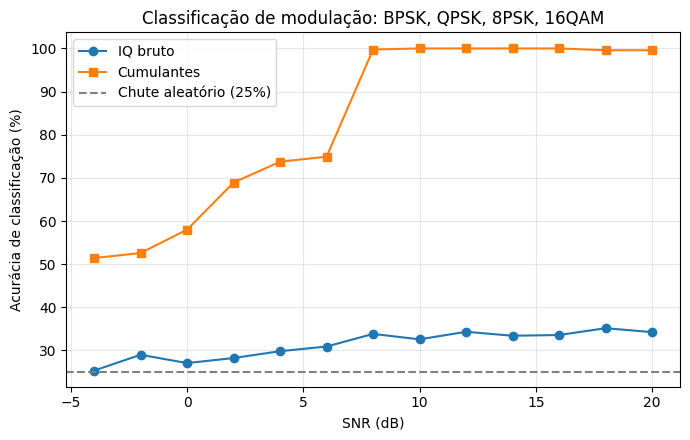

In [ ]:
"""
Classificação automática de modulação (AMC) com redes neurais - Passo 1
=======================================================================
Objetivo: simular sinais BPSK, QPSK, 8PSK e 16QAM em canal AWGN e treinar
uma rede neural para descobrir qual modulação foi usada.

Requisitos: numpy, scikit-learn, matplotlib
    pip install numpy scikit-learn matplotlib

Como rodar:
    python classificador_modulacao.py
"""

import numpy as np
import matplotlib.pyplot as plt
from sklearn.neural_network import MLPClassifier
from sklearn.preprocessing import StandardScaler

rng = np.random.default_rng(42)  # semente fixa: resultados reproduzíveis

# ----------------------------------------------------------------------
# 1) CONSTELAÇÕES (símbolos complexos com potência média = 1)
# ----------------------------------------------------------------------
def constelacao(nome):
    if nome == "BPSK":
        pts = np.array([1, -1], dtype=complex)
    elif nome == "QPSK":
        pts = np.exp(1j * (np.pi / 4 + np.pi / 2 * np.arange(4)))
    elif nome == "8PSK":
        pts = np.exp(1j * 2 * np.pi * np.arange(8) / 8)
    elif nome == "16QAM":
        niveis = np.array([-3, -1, 1, 3])
        pts = (niveis[:, None] + 1j * niveis[None, :]).ravel()
    else:
        raise ValueError(nome)
    return pts / np.sqrt(np.mean(np.abs(pts) ** 2))  # normaliza a potência


MODULACOES = ["BPSK", "QPSK", "8PSK", "16QAM"]
CONSTELACOES = {m: constelacao(m) for m in MODULACOES}

# -2 GERAÇÃO DE UM EXEMPLO: símbolos aleatórios + ruído AWGN
def gera_sinal(mod, n_simbolos, snr_db):
    simbolos = rng.choice(CONSTELACOES[mod], size=n_simbolos)
    snr_lin = 10 ** (snr_db / 10)
    sigma = np.sqrt(1 / (2 * snr_lin))  # variância do ruído por componente (I e Q)
    ruido = sigma * (rng.standard_normal(n_simbolos) + 1j * rng.standard_normal(n_simbolos))
    return simbolos + ruido


# -3 EXTRAÇÃO DE CARACTERÍSTICAS
#    (a) IQ bruto: a rede aprende sozinha (precisa de mais dados)
#    (b) Cumulantes de ordem superior: características clássicas de AMC

def iq_bruto(x):
    return np.concatenate([x.real, x.imag])


def cumulantes(x):
    x = x / np.sqrt(np.mean(np.abs(x) ** 2))  # normaliza a potência
    c20 = np.mean(x ** 2)
    c21 = np.mean(np.abs(x) ** 2)
    c40 = np.mean(x ** 4) - 3 * c20 ** 2
    c41 = np.mean(x ** 3 * np.conj(x)) - 3 * c20 * c21
    c42 = np.mean(np.abs(x) ** 4) - np.abs(c20) ** 2 - 2 * c21 ** 2
    return np.array([np.abs(c20), np.abs(c40), np.abs(c41), c42.real])


#-4 MONTAGEM DO CONJUNTO DE DADOS

def monta_dataset(n_por_classe, n_simbolos, snrs_db, extrator):
    X, y, snr_lista = [], [], []
    for idx, mod in enumerate(MODULACOES):
        for _ in range(n_por_classe):
            snr = rng.choice(snrs_db)
            X.append(extrator(gera_sinal(mod, n_simbolos, snr)))
            y.append(idx)
            snr_lista.append(snr)
    return np.array(X), np.array(y), np.array(snr_lista)


# -g5 TREINO E AVALIAÇÃO
N_SIMBOLOS = 512
SNRS_TREINO = np.arange(-4, 21, 2)   # de -4 dB a 20 dB
SNRS_TESTE = np.arange(-4, 21, 2)


def treina_e_avalia(extrator, nome):
    print(f"\n=== Modelo com características: {nome} ===")
    Xtr, ytr, _ = monta_dataset(1500, N_SIMBOLOS, SNRS_TREINO, extrator)
    escala = StandardScaler().fit(Xtr)
    rede = MLPClassifier(hidden_layer_sizes=(64, 64), max_iter=300,
                         early_stopping=True, random_state=0)
    rede.fit(escala.transform(Xtr), ytr)

    # acurácia para cada SNR separadamente
    acc_por_snr = []
    for snr in SNRS_TESTE:
        Xte, yte, _ = monta_dataset(300, N_SIMBOLOS, [snr], extrator)
        acc = rede.score(escala.transform(Xte), yte)
        acc_por_snr.append(acc)
        print(f"SNR = {snr:3d} dB  ->  acurácia = {acc * 100:5.1f}%")
    return acc_por_snr


if __name__ == "__main__":
    acc_iq = treina_e_avalia(iq_bruto, "IQ bruto")
    acc_cum = treina_e_avalia(cumulantes, "Cumulantes")

    plt.figure(figsize=(7, 4.5))
    plt.plot(SNRS_TESTE, np.array(acc_iq) * 100, "o-", label="IQ bruto")
    plt.plot(SNRS_TESTE, np.array(acc_cum) * 100, "s-", label="Cumulantes")
    plt.axhline(25, color="gray", ls="--", label="Chute aleatório (25%)")
    plt.xlabel("SNR (dB)")
    plt.ylabel("Acurácia de classificação (%)")
    plt.title("Classificação de modulação: BPSK, QPSK, 8PSK, 16QAM")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.savefig("acuracia_vs_snr.png", dpi=150)
    print("\nGráfico salvo em acuracia_vs_snr.png")

    def iq_ordenado(x):
      return np.concatenate([np.sort(x.real), np.sort(x.imag)])

acc_ord = treina_e_avalia(iq_ordenado, "IQ ordenado")
